# **Indonesian Traffic Sign Recognition Using YOLOv8**

In [1]:
pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 31.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]
Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 92.7 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [roboflow]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


# **2. Dataset Acquisition & Configuration**

In [3]:
data = {
    'train': "/kaggle/input/datasets/nanadiaa14/stc-project/train",
    'valid': "/kaggle/input/datasets/nanadiaa14/stc-project/valid",
    'test': "/kaggle/input/datasets/nanadiaa14/stc-project/test",
    'nc': 5,
    'names': ['dilarang-belok-kanan', 'dilarang-berhenti', 'dilarang-masuk', 'jalur-penyebrangan', 'peringatan-lampu-merah']
}


## **3. Model Initialization & Training (YOLOv8n — 100 Epochs)**

In [4]:
from ultralytics import YOLO

# Muat model pre-trained (disarankan untuk training)
model = YOLO('yolov8n.pt')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [5]:
project_dir_in_drive = '/kaggle/working/Traffic_Sign_Recognition_YOLOv8_Result'
project_name = 'traffic-sign-recognition_yolov8_training'
experiment_name = 'augmentation_training_v2'

In [6]:
import os

results = model.train(
    data='/kaggle/input/datasets/nanadiaa14/stc-project/data.yaml',
    epochs=100,
    imgsz=640,
    batch=16,
    name=experiment_name,
    project=os.path.join(project_dir_in_drive, project_name),
    cache=True,
    device=0
)

final_save_path = os.path.join(project_dir_in_drive, project_name, experiment_name)
print(f"Training selesai. Semua hasil (model, log, grafik) disimpan di: {final_save_path}")


Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/input/datasets/nanadiaa14/stc-project/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=augmentation_training_v2, nbs=64

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


      2/100       2.6G      1.176       1.19      1.294         32        640: 100% ━━━━━━━━━━━━ 87/87 9.6it/s 9.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 7.9it/s 0.6s
                   all        133        133       0.75      0.781      0.872      0.549

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/100       2.6G      1.206     0.9997      1.288         21        640: 100% ━━━━━━━━━━━━ 87/87 9.5it/s 9.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 8.3it/s 0.6s
                   all        133        133       0.67      0.824      0.881       0.58

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      4/100       2.6G       1.18     0.9071      1.267         21        640: 100% ━━━━━━━━━━━━ 87/87 9.6it/s 9.1s
                 Class     Images  Instances      Box(P          R

# **Model Evaluation**

In [7]:
model_to_evaluate_path = os.path.join(project_dir_in_drive, project_name, experiment_name, 'weights', 'best.pt')
{model_to_evaluate_path}

{'/kaggle/working/Traffic_Sign_Recognition_YOLOv8_Result/traffic-sign-recognition_yolov8_training/augmentation_training_v2/weights/best.pt'}

In [8]:
model = YOLO(model_to_evaluate_path)

print("\nMemulai evaluasi pada dataset TEST...")
metrics = model.val(
    data='/kaggle/input/datasets/nanadiaa14/stc-project/data.yaml',
    split='test',
    imgsz=640,
    batch=16,
    device=0,
)

print("\n--- Hasil Evaluasi ---")
print(f"mAP50-95 (Average Precision across IoU thresholds from 0.5 to 0.95): {metrics.box.map}")
print(f"mAP50 (Average Precision at IoU threshold 0.5): {metrics.box.map50}")
print(f"mAP75 (Average Precision at IoU threshold 0.75): {metrics.box.map75}")


Memulai evaluasi pada dataset TEST...
Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.3±0.0 ms, read: 0.2±0.2 MB/s, size: 46.0 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/input/datasets/nanadiaa14/stc-project/test/labels... 68 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 68/68 4.9it/s 13.8s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/nanadiaa14/stc-project/test is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.3s/it 11.5s
                   all         68         68      0.993      0.988      0.995      0.733
  dilarang-belok-kanan         13         13      0.995          1      0.995    

## **Visualization**

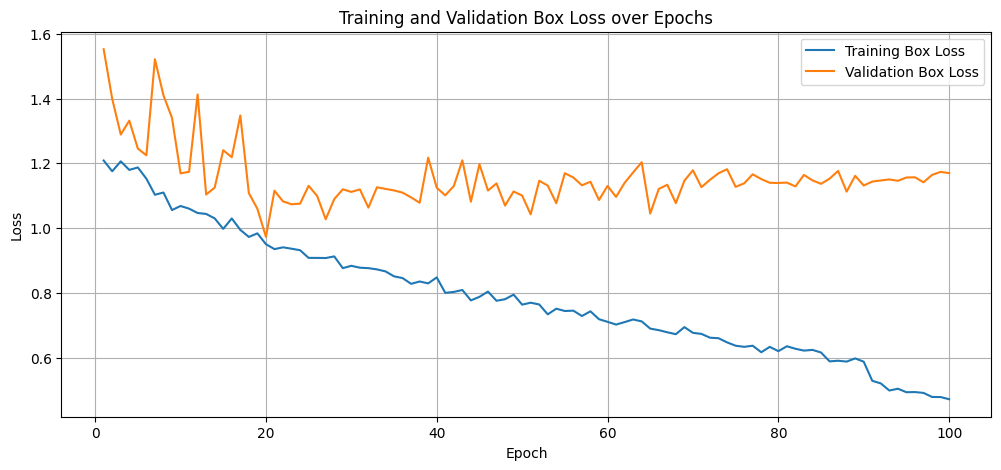

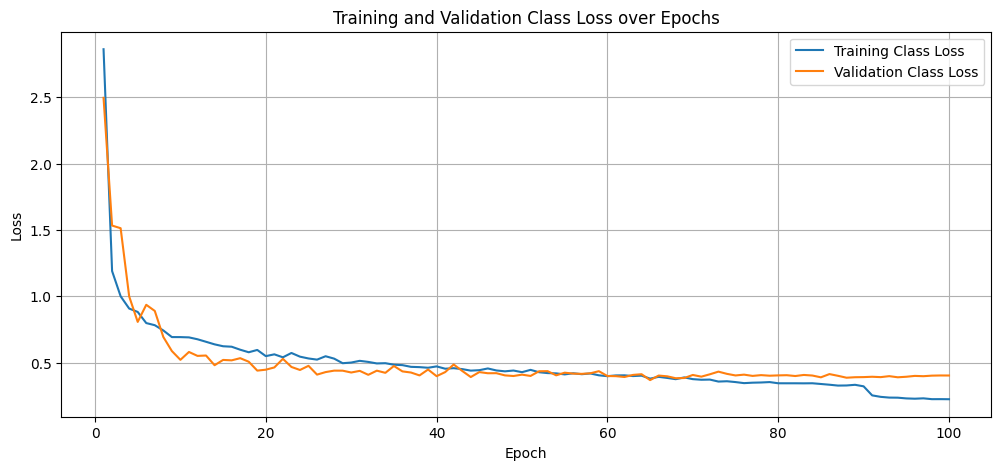

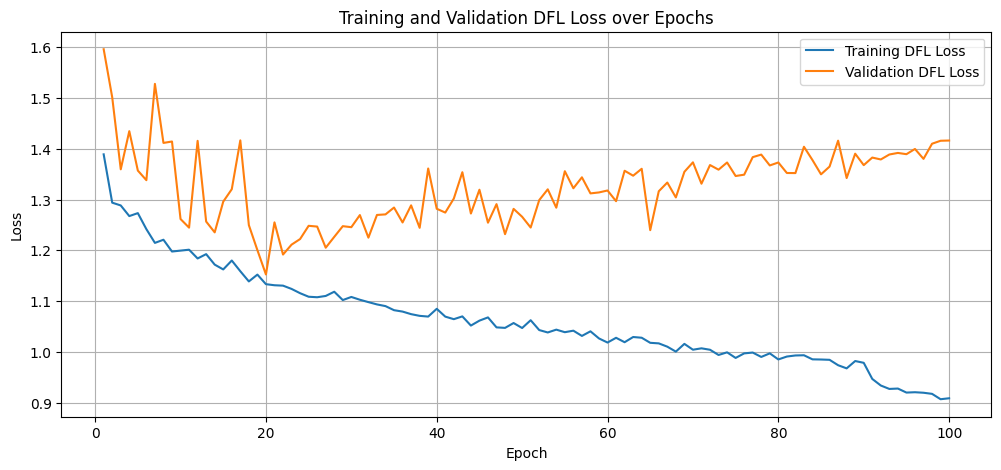

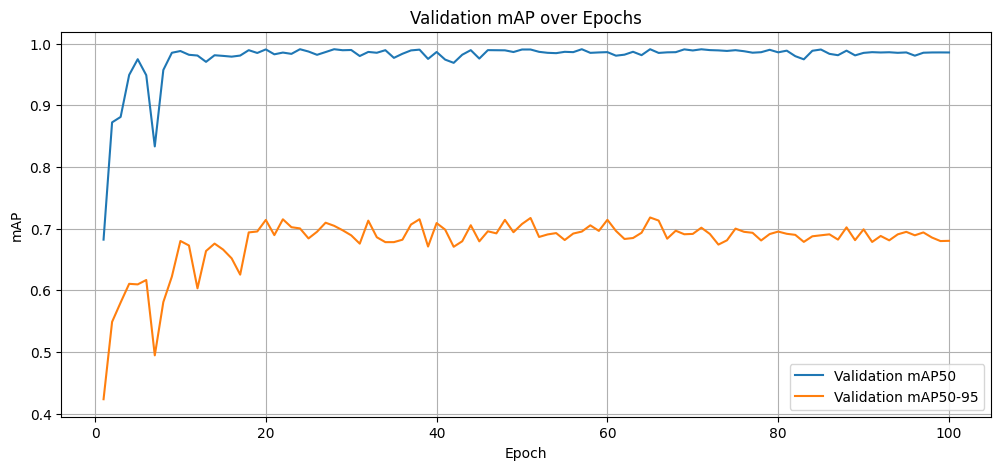

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# Define the path to the results.csv file
results_csv_path = "/kaggle/working/Traffic_Sign_Recognition_YOLOv8_Result/traffic-sign-recognition_yolov8_training/augmentation_training_v2/results.csv"

# Read the results.csv file
results_df = pd.read_csv(results_csv_path)

# Clean column names (remove leading/trailing spaces)
results_df.columns = results_df.columns.str.strip()

# Plot Training and Validation Box Loss
plt.figure(figsize=(12, 5))
plt.plot(results_df['epoch'], results_df['train/box_loss'], label='Training Box Loss')
plt.plot(results_df['epoch'], results_df['val/box_loss'], label='Validation Box Loss')
plt.title('Training and Validation Box Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# Plot Training and Validation Class Loss
plt.figure(figsize=(12, 5))
plt.plot(results_df['epoch'], results_df['train/cls_loss'], label='Training Class Loss')
plt.plot(results_df['epoch'], results_df['val/cls_loss'], label='Validation Class Loss')
plt.title('Training and Validation Class Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# Plot Training and Validation DFL Loss
plt.figure(figsize=(12, 5))
plt.plot(results_df['epoch'], results_df['train/dfl_loss'], label='Training DFL Loss')
plt.plot(results_df['epoch'], results_df['val/dfl_loss'], label='Validation DFL Loss')
plt.title('Training and Validation DFL Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()


# Plot mAP50 and mAP50-95
plt.figure(figsize=(12, 5))
plt.plot(results_df['epoch'], results_df['metrics/mAP50(B)'], label='Validation mAP50')
plt.plot(results_df['epoch'], results_df['metrics/mAP50-95(B)'], label='Validation mAP50-95')

plt.title('Validation mAP over Epochs')
plt.xlabel('Epoch')
plt.ylabel('mAP')
plt.legend()
plt.grid(True)
plt.show()